# Lesson 8.2: Simple Linear Regression: Drawing the Best Line

Fit the least-squares line that predicts exam score from study hours (the lesson's eight students) and use it to predict the score for 6.5 hours.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## 1. Enter the data

Hours studied (x) is the predictor and the exam score (y) is what we want to predict. Same eight students as in the correlation lesson.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

hours = np.array([1, 2, 3, 4, 5, 6, 7, 8])
score = np.array([48, 62, 55, 66, 63, 74, 70, 82])

print('students:', len(hours))
print('mean hours =', hours.mean(), ' mean score =', score.mean())

students: 8
mean hours = 4.5  mean score = 65.0


## 2. Fit the line with linregress

linregress finds the slope and intercept that make the squared vertical misses as small as possible. The slope is the typical gain in score for one extra hour. Its p-value tests whether the true slope is 0.

In [2]:
fit = stats.linregress(hours, score)

print(f'slope     = {fit.slope:.3f}')
print(f'intercept = {fit.intercept:.3f}')
print(f'r         = {fit.rvalue:.3f}')
print(f'p-value   = {fit.pvalue:.4f}')
print(f'std error of slope = {fit.stderr:.3f}')

slope     = 3.952
intercept = 47.214
r         = 0.907
p-value   = 0.0019
std error of slope = 0.750


## 3. Predict a new value

To predict, put a new x into the line: score = intercept + slope x hours. 6.5 hours is inside the 1 to 8 hours we measured, so this is safe interpolation. Predicting for 20 hours would be extrapolation and should not be trusted.

In [3]:
new_hours = 6.5
predicted = fit.intercept + fit.slope * new_hours

print(f'predicted score for {new_hours} hours = {predicted:.1f}')
print(f'at the mean hours (4.5) the line gives {fit.intercept + fit.slope * 4.5:.1f}')

predicted score for 6.5 hours = 72.9
at the mean hours (4.5) the line gives 65.0


## 4. Draw the data and the line

The line should run through the middle of the points, passing through the point of means. The new prediction is marked with a star.

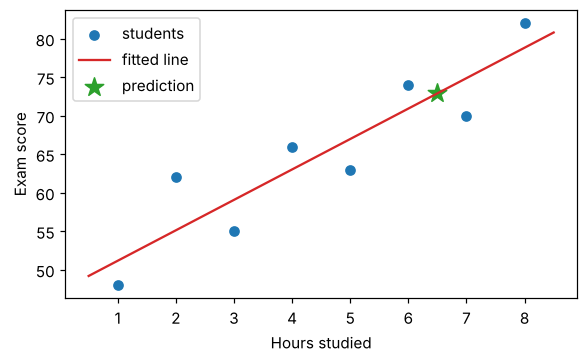

In [4]:
x_line = np.array([0.5, 8.5])

plt.figure(figsize=(6, 3.4))
plt.scatter(hours, score, color='#1f77b4', label='students')
plt.plot(x_line, fit.intercept + fit.slope * x_line, color='#d62728', label='fitted line')
plt.scatter([new_hours], [predicted], marker='*', s=160, color='#2ca02c', label='prediction')
plt.xlabel('Hours studied')
plt.ylabel('Exam score')
plt.legend()
plt.show()

## Try this

- Predict the score for 20 hours. Is the answer believable? Why is this called extrapolation?
- Change the first score from 48 to 30. Predict which of slope and intercept moves more, then run it.

## The same idea in R, SPSS and Stata

**R**

```r
hours <- c(1, 2, 3, 4, 5, 6, 7, 8)
score <- c(48, 62, 55, 66, 63, 74, 70, 82)
fit <- lm(score ~ hours)
summary(fit)
predict(fit, data.frame(hours = 6.5))
```

**SPSS** (Analyze > Regression > Linear (Dependent: score, Independent: hours))

```
DATA LIST FREE / hours score.
BEGIN DATA
1 48  2 62  3 55  4 66  5 63  6 74  7 70  8 82
END DATA.
REGRESSION
  /STATISTICS COEFF R ANOVA
  /DEPENDENT score
  /METHOD=ENTER hours.
```

**Stata**

```
clear
set obs 8
generate hours = _n
generate score = real(word("48 62 55 66 63 74 70 82", _n))
regress score hours
display _b[_cons] + _b[hours] * 6.5
twoway (scatter score hours) (lfit score hours)
```